# Домашняя работа 6. Служба безопасности и поддержка банка

Две задачи банка: по переводу понять, мошенничество ли это (kNN), и разослать письма клиентов по отделам (наивный Байес).
Данные у каждого свои — зависят от фамилии.

- **Обязательно — задания 1–4.**
- **По желанию — задания 5–6.** На зачёт не влияют; если не делаете, оставьте в них `...`.

Срок — до следующего занятия. Защита устная: преподаватель просит что-то поменять в ноутбуке (например, число соседей) и объяснить результат.
Код и ответы друг другу не передавать.

## Что сдать

1. Ноутбук проходит сверху вниз (*Restart & Run All*), «Проверка» заданий 1–4 печатает «пройдена». Имя файла — как печатает ячейка варианта (`hw06_Ivanov.ipynb`).
2. Под каждым сделанным заданием — **Вывод** в 1–2 предложения с вашими числами.
3. Последнюю ячейку (`СВОДКА …`) не меняйте.

In [ ]:
# Служебная ячейка: импорты, стиль графиков, файлы курса (варианты и генератор данных).
import inspect, sys, pathlib, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True

COURSE_FILES_URL = "https://raw.githubusercontent.com/sharipovaka/ml_labs/main/notebooks"


def course_file(name, folder=""):
    # файл курса: ищем рядом (и в папке data), иначе скачиваем из репозитория курса
    for parent in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents][:4]:
        for candidate in (parent / name, parent / "data" / name):
            if candidate.exists():
                return candidate
    urllib.request.urlretrieve(f"{COURSE_FILES_URL}/{folder}{name}", name)
    return pathlib.Path(name)


sys.path.insert(0, str(course_file("variants.py").parent))
sys.path.insert(0, str(course_file("bank_data.py").parent))
from variants import get_variant, submission_name  # noqa: E402
from bank_data import make_transfers, make_requests  # noqa: E402

## Индивидуальный вариант

Впишите фамилию так, как в списке группы. От строки зависят данные. Регистр, лишние пробелы и «ё»/«е» роли не играют. Однофамильцам нужно добавить инициал (`Петрова А.`).

In [ ]:
STUDENT = "Фамилия"   # <-- впишите свою фамилию

assert STUDENT.strip() != "Фамилия", "Впишите свою фамилию в переменную STUDENT"

VARIANT = get_variant(STUDENT, lab=6)
print("seed данных:", VARIANT["seed"])
print("Сдавать под именем:", submission_name(STUDENT, lab=6))

### Данные 1: переводы

| столбец | что это |
|---|---|
| `amount` | сумма перевода, руб. |
| `hour` | час перевода (0–23) |
| `new_recipient` | получатель новый — раньше ему не переводили (1/0) |
| `per_hour` | сколько ещё переводов клиент сделал за последний час |
| `recipient_days` | сколько дней назад открыт счёт получателя |
| `weekday` | день недели (1 — понедельник) |
| `fraud` | **ответ: 1 — мошенничество**, 0 — честный перевод |

`X_train`, `y_train` — 600 переводов для обучения; `X_test`, `y_test` — 200 для теста.
**Тест не трогаем до пункта 3 задания 2**: всё выбираем по кросс-валидации на обучении, иначе оценка на тесте выйдет завышенной.
`cv5` — разбиение для кросс-валидации, используйте его во всех заданиях.

In [ ]:
FEATURES = ["amount", "hour", "new_recipient", "per_hour", "recipient_days", "weekday"]

transfers = make_transfers(800, seed=VARIANT["seed"])   # ваши 800 переводов
train, test = train_test_split(transfers, test_size=0.25, random_state=VARIANT["seed"], stratify=transfers["fraud"])
X_train, y_train = train[FEATURES], train["fraud"].to_numpy()
X_test, y_test = test[FEATURES], test["fraud"].to_numpy()
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)

print("обучение:", X_train.shape, " тест:", X_test.shape)
print("доля мошенничества в обучении:", round(y_train.mean(), 3),
      " → правило «все переводы честные» угадывает", round(1 - y_train.mean(), 3))
train.head()

---
# Обязательная часть (задания 1–4)

## Задание 1. Рубли против часов

Коллега взял kNN с 5 соседями и все признаки как есть — вышло на уровне правила «все переводы честные», а то и хуже.

1. `cv_raw` — доля верных по кросс-валидации `cv5` у `KNeighborsClassifier(n_neighbors=5)` на `X_train` **без масштабирования** (как у коллеги).
2. `cv_scaled` — то же, но с масштабированием: `make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))`, как в части 3 лабы.
3. `loud_feature` — признак, который «перекрикивает» остальные: у него самый большой разброс (смотрите строку `std` в таблице ниже). Впишите название строкой.

In [ ]:
X_train.describe().round(1)

In [ ]:
cv_raw = ...       # TODO: доля верных kNN(5) без масштабирования по кросс-валидации cv5
cv_scaled = ...    # TODO: то же с StandardScaler (make_pipeline)
loud_feature = ... # TODO: название признака с наибольшим std — строкой, например "hour"
if cv_scaled is not ...:
    print("без масштабирования:", round(cv_raw, 3), " с масштабированием:", round(cv_scaled, 3),
          " «все честные»:", round(1 - y_train.mean(), 3))

Кого kNN без масштабирования считает «соседями» мошеннического перевода:

In [ ]:
raw5 = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
dist, idx = raw5.kneighbors()   # 5 соседей каждого перевода из обучения (сам перевод не в счёт)
i = np.where((y_train == 1) & (y_train[idx].mean(axis=1) < 0.5))[0][0]   # мошенник, а соседи в основном честные
print("мошеннический перевод:")
display(train.iloc[[i]])
print("его 5 «соседей» без масштабирования:")
train.iloc[idx[i]].assign(расстояние=dist[i].round(1))

In [ ]:
# Проверка задания 1 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
assert 0 < cv_raw <= 1 and 0 < cv_scaled <= 1, "cv_raw, cv_scaled — доли верных, от 0 до 1"
assert cv_scaled > cv_raw, "с масштабированием должно выйти лучше: проверьте, что в cv_scaled есть StandardScaler"
assert loud_feature in FEATURES, f"loud_feature — одно из {FEATURES}"
print("Проверка задания 1 пройдена")

**Вывод.** *(1–2 предложения с числами: чем похожи «соседи» из таблицы выше и сколько дал `StandardScaler`.)*

---
## Задание 2. Сколько соседей

Дальше — только с масштабированием.

1. Для `k` из списка `KS` — доля верных по кросс-валидации `cv5` у `make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))` → `cv_k` (график уже написан).
2. `best_k` — `k` с наибольшей `cv_k`, `cv_best` — эта доля.
3. Только теперь **один раз** открываем тест: обучите модель с `best_k` на всём обучении → доля верных на тесте `test_knn`.
4. `caught` — какую долю **настоящих мошенничеств** из теста модель поймала (ответила 1). Подсказка: `pred[y_test == 1].mean()`, где `pred` — ответы модели на `X_test`.

In [ ]:
KS = [1, 3, 5, 7, 11, 15, 21, 31, 51, 75, 101]
cv_k = []
for k in KS:
    # TODO: добавьте в cv_k долю верных по кросс-валидации cv5 у модели с масштабированием и k соседями
    ...
cv_k = np.array(cv_k)
best_k = ...   # TODO: k из KS с наибольшей cv_k
cv_best = ...  # TODO: наибольшая cv_k

plt.plot(range(len(KS)), cv_k, "s-", label="кросс-валидация")
plt.axhline(1 - y_train.mean(), c="gray", ls="--", label="«все честные»")
plt.xticks(range(len(KS)), KS)
plt.xlabel("число соседей k")
plt.ylabel("доля верных")
plt.legend()
plt.show()

In [ ]:
final = ...      # TODO: модель с масштабированием и best_k соседями, обученная на всём обучении
pred = ...       # TODO: её ответы на X_test
test_knn = ...   # TODO: доля верных на тесте
caught = ...     # TODO: доля пойманных среди настоящих мошенничеств теста
if caught is not ...:
    print("k =", best_k, " тест:", round(test_knn, 3), " поймано мошенничеств:", round(caught, 3),
          f"({int(pred[y_test == 1].sum())} из {int((y_test == 1).sum())})")

In [ ]:
# Проверка задания 2 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
assert len(cv_k) == len(KS) and ((0 < cv_k) & (cv_k <= 1)).all(), "cv_k — по одной доле верных на каждое k из KS"
assert cv_k[0] < 0.95, "у k = 1 почти 1.0 — похоже на долю на обучении, а нужна кросс-валидация"
assert best_k in KS and np.isclose(cv_k[KS.index(best_k)], cv_k.max()), "best_k — k с наибольшей cv_k"
assert np.isclose(cv_best, cv_k.max()), "cv_best — наибольшая cv_k"
assert len(pred) == len(y_test), "pred — ответы модели на X_test"
assert np.isclose(test_knn, (np.asarray(pred) == y_test).mean()), "test_knn — доля верных ответов pred на тесте"
assert np.isclose(caught, np.asarray(pred)[y_test == 1].mean()), "caught — доля единиц в pred среди настоящих мошенничеств"
print("Проверка задания 2 пройдена")

Доля верных и доля пойманных — разные вещи: честных переводов больше, на них и набирается доля верных.

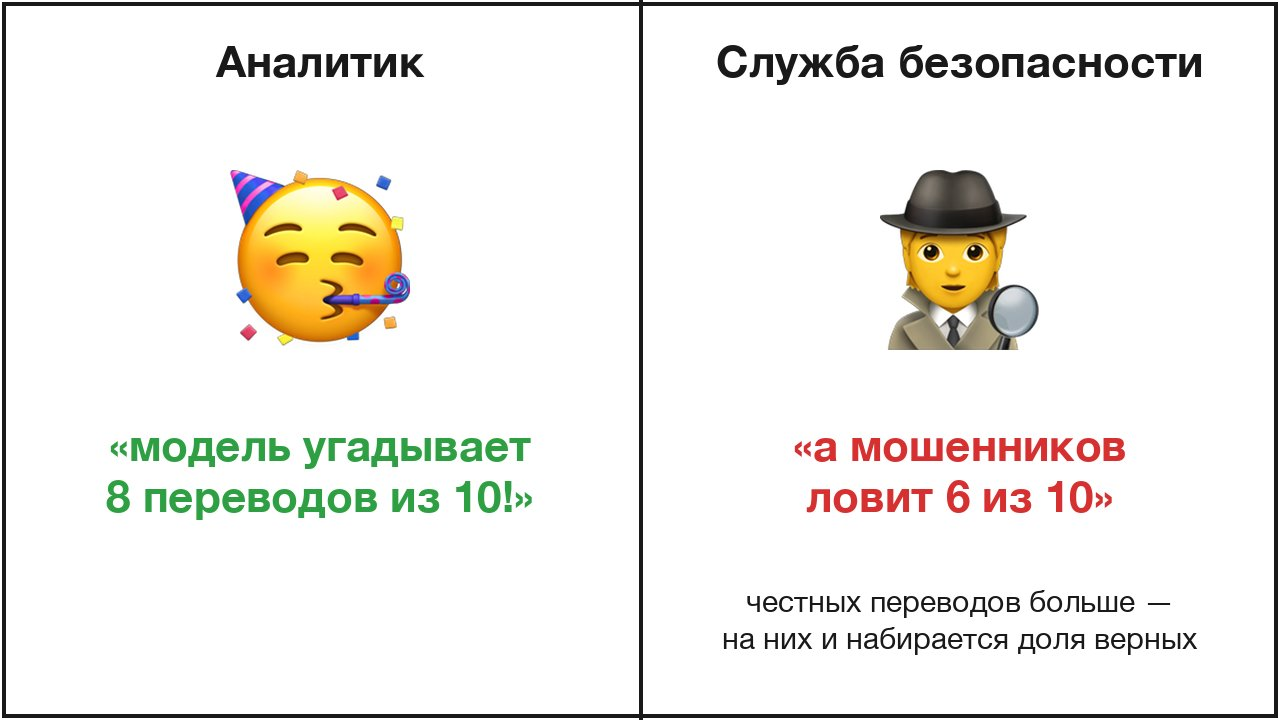

**Вывод.** *(1–2 предложения с числами: какое `k` выбрали, насколько это лучше «все честные» и сколько мошенничеств из теста модель пропустила.)*

---
## Задание 3. Разбор обращений

Письма в поддержку: наивный Байес, как спам-фильтр в лабе, только отделов четыре (карты, кредиты, вклады, приложение).

In [ ]:
requests = make_requests(600, seed=VARIANT["seed"])   # ваши 600 писем
r_train, r_test = train_test_split(requests, test_size=0.25, random_state=VARIANT["seed"], stratify=requests["dept"])
print("обучение:", len(r_train), " тест:", len(r_test))
print(r_train["dept"].value_counts(normalize=True).round(3).to_string())
r_train.head(8)

1. `nb_model = make_pipeline(CountVectorizer(), MultinomialNB())` — «считаем слова → наивный Байес» одной моделью.
2. `cv_nb` — доля верных по кросс-валидации `cv5` на `r_train["text"]`, `r_train["dept"]`.
3. Обучите `nb_model` на всём `r_train` → доля верных на тесте `test_nb`.
4. `top_word_credit` — по таблице ниже: какое слово сильнее всех голосует за отдел «кредиты» (первое в его строке). Впишите строкой; если у первых слов одинаковое «×», подойдёт любое из них.

In [ ]:
nb_model = ...   # TODO: CountVectorizer + MultinomialNB одной моделью
cv_nb = ...      # TODO: доля верных по кросс-валидации cv5 на текстах r_train
# TODO: обучите nb_model на r_train
test_nb = ...    # TODO: доля верных на тесте r_test
if test_nb is not ...:
    print("кросс-валидация:", round(cv_nb, 3), " тест:", round(test_nb, 3),
          " «всё в самый частый отдел»:", round(r_train["dept"].value_counts(normalize=True).max(), 3))

In [ ]:
# Слова-голоса: во сколько раз слово чаще в письмах этого отдела, чем в среднем в остальных (по обученной nb_model)
if test_nb is not ...:
    _vec, _nb = nb_model[0], nb_model[1]
    _words = _vec.get_feature_names_out()
    _lp = _nb.feature_log_prob_
    votes = {}
    for _i, _d in enumerate(_nb.classes_):
        _ratio = np.exp(_lp[_i] - np.delete(_lp, _i, axis=0).mean(axis=0))
        _top = np.argsort(-_ratio, kind="stable")[:6]
        votes[_d] = [f"{_words[j]} ×{_ratio[j]:.0f}" for j in _top]
    display(pd.DataFrame(votes).T.set_axis([f"{j + 1}-е" for j in range(6)], axis=1))

In [ ]:
top_word_credit = ...   # TODO: первое слово в строке «кредиты» — строкой

А вот письма из теста, на которых модель ошиблась:

In [ ]:
if test_nb is not ...:
    _pred = nb_model.predict(r_test["text"])
    display(r_test.assign(модель=_pred)[_pred != r_test["dept"]].rename(columns={"dept": "на самом деле"}).head(8))

In [ ]:
# Проверка задания 3 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
assert 0 < cv_nb <= 1 and 0 < test_nb <= 1, "cv_nb, test_nb — доли верных, от 0 до 1"
assert np.isclose(test_nb, nb_model.score(r_test["text"], r_test["dept"])), "test_nb — доля верных nb_model на r_test"
_lp = nb_model[1].feature_log_prob_
_i = list(nb_model[1].classes_).index("кредиты")
_score = dict(zip(nb_model[0].get_feature_names_out(), _lp[_i] - np.delete(_lp, _i, axis=0).mean(axis=0)))
assert top_word_credit in _score and np.isclose(_score[top_word_credit], max(_score.values())), \
    "top_word_credit — первое слово в строке «кредиты» (без «×…»)"
print("Проверка задания 3 пройдена")

**Вывод.** *(1–2 предложения с числами: насколько Байес лучше «всё в самый частый отдел» и почему он ошибся на письмах из таблицы.)*

---
## Задание 4. Раскрываем карты

Ниже — генератор ваших переводов (`bank_data.py`). Чем больше `logit`, тем вероятнее мошенничество: плюс — признак повышает риск, минус — снижает.
`night` — с 23 до 5 часов; `weekday` в формулу не входит.

Уберём признаки по одному и посмотрим, насколько упадёт доля верных kNN.

1. `drop_loss` — Series по `FEATURES`: для каждого признака `cv_best` минус доля верных по `cv5` модели с масштабированием и `best_k` соседями
   **без этого признака** (положительное число — признак нужен, отрицательное — без него даже лучше).
2. `most_needed` — признак с наибольшей `drop_loss`; `loss_weekday` — `drop_loss` у `weekday`.

In [ ]:
print(inspect.getsource(make_transfers))

In [ ]:
drop_loss = ...      # TODO: Series по FEATURES: cv_best − доля верных по cv5 без признака (X_train.drop(columns=f))
most_needed = ...    # TODO: признак с наибольшей drop_loss
loss_weekday = ...   # TODO: drop_loss у weekday
if drop_loss is not ...:
    print("нужнее всего:", most_needed, " день недели:", round(loss_weekday, 3))
    drop_loss.sort_values().plot.barh(color=["C3" if f == "weekday" else "gray" for f in drop_loss.sort_values().index])
    plt.axvline(0, c="k", lw=1)
    plt.xlabel("насколько падает доля верных без признака")
    plt.title("Какие признаки нужны kNN (weekday — красный)")
    plt.show()

In [ ]:
# Проверка задания 4 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
assert isinstance(drop_loss, pd.Series) and set(drop_loss.index) == set(FEATURES), "drop_loss — Series с индексом FEATURES"
assert (drop_loss.abs() < 0.3).all(), "drop_loss — разность долей верных (с признаком минус без), числа около нуля"
assert np.isclose(drop_loss[most_needed], drop_loss.max()), "most_needed — признак с наибольшей drop_loss"
assert np.isclose(loss_weekday, drop_loss["weekday"]), "loss_weekday — drop_loss у weekday"
print("Проверка задания 4 пройдена")

**Вывод.** *(1–2 предложения: какой признак нужнее всего — совпадает ли с формулой? По формуле ночь почти так же важна, как новый получатель
(3.5 против 4.0). Сравните `drop_loss` у `hour` и у `new_recipient`: если `hour` kNN нужен меньше, почему?
Подсказка: для kNN часы 13 и 17 различаются так же, как 3 и 7, а по формуле важно только «ночь или нет».)*

---
# По желанию (задания 5–6)

На зачёт не влияют. Если не делаете — оставьте `...`, ноутбук всё равно пройдёт до конца.

## Задание 5 (по желанию). Письмо про два отдела

Клиент пишет: *«Здравствуйте. Не могу войти в приложение, а надо внести платёж по кредиту»*.

1. `p_letter` — вероятности отделов для этого письма: `nb_model.predict_proba([LETTER])[0]`.
2. `letter_dept` — отдел с наибольшей вероятностью, строкой.
3. `key_word` — слово письма, которое сильнее всех тянет его в `letter_dept` (по готовой таблице `word_votes`).

In [ ]:
LETTER = "Здравствуйте. Не могу войти в приложение, а надо внести платёж по кредиту"
p_letter = ...      # TODO: вероятности отделов для LETTER
letter_dept = ...   # TODO: отдел с наибольшей вероятностью — строкой
if p_letter is not ...:
    display(pd.Series(p_letter, index=nb_model.classes_).round(3).to_frame("вероятность").T)

# как голосует каждое слово письма (слова, которых модель не видела, не голосуют)
_vec, _nb = nb_model[0], nb_model[1]
_lp = _nb.feature_log_prob_
_known = [w for w in _vec.build_analyzer()(LETTER) if w in _vec.vocabulary_]
word_votes = pd.DataFrame({_d: [np.exp(_lp[_i, _vec.vocabulary_[w]] - np.delete(_lp, _i, axis=0)[:, _vec.vocabulary_[w]].mean())
                                for w in _known] for _i, _d in enumerate(_nb.classes_)}, index=_known)
word_votes.round(1)

In [ ]:
key_word = ...   # TODO: слово с наибольшим голосом за letter_dept — строкой

In [ ]:
# Проверка задания 5 (не меняйте эту ячейку)
if p_letter is ...:
    print("Задание 5 не делали — пропускаем")
else:
    assert np.isclose(np.sum(p_letter), 1) and len(p_letter) == 4, "p_letter — 4 вероятности отделов"
    assert letter_dept == nb_model.classes_[np.argmax(p_letter)], "letter_dept — отдел с наибольшей вероятностью"
    assert key_word in word_votes.index, "key_word — слово из таблицы word_votes"
    assert np.isclose(word_votes.loc[key_word, letter_dept], word_votes[letter_dept].max()), f"key_word: какое слово сильнее всех голосует за «{letter_dept}»?"
    print("Проверка задания 5 пройдена")

**Вывод.** *(1–2 предложения: куда ушло письмо, какое слово перетянуло и куда отправил бы его живой оператор.)*

---
## Задание 6 (по желанию). Почините признаки

Улучшите kNN, **не трогая модель** — только признаки.

1. `X_fixed` — копия `X_train`, где вместо `hour` стоит признак `night` (1, если `hour <= 5` или `hour >= 23`, иначе 0 — как в формуле), а `weekday` убран.
2. `cv_fixed` — доля верных по `cv5` у модели с масштабированием и `best_k` соседями на `X_fixed`.
3. `gain_fixed` — `cv_fixed − cv_best`: сколько дала починка.

In [ ]:
X_fixed = ...      # TODO: X_train с night вместо hour и без weekday
cv_fixed = ...     # TODO: доля верных по cv5 (масштаб + best_k соседей) на X_fixed
gain_fixed = ...   # TODO: cv_fixed − cv_best
if gain_fixed is not ...:
    print("было:", round(cv_best, 3), " стало:", round(cv_fixed, 3), " выигрыш:", round(gain_fixed, 3))

In [ ]:
# Проверка задания 6 (не меняйте эту ячейку): только согласованность ответов, верность чисел проверит преподаватель
if X_fixed is ...:
    print("Задание 6 не делали — пропускаем")
else:
    assert "night" in X_fixed.columns and "hour" not in X_fixed.columns and "weekday" not in X_fixed.columns, \
        "в X_fixed должен быть night, а hour и weekday — нет"
    assert set(X_fixed["night"].unique()) <= {0, 1}, "night — 0 или 1"
    assert 0 < cv_fixed <= 1 and np.isclose(gain_fixed, cv_fixed - cv_best), "gain_fixed = cv_fixed − cv_best"
    print("Проверка задания 6 пройдена")

**Вывод.** *(1–2 предложения с числами: сколько дала починка и почему `night` помогает, хотя в нём меньше информации, чем в `hour`; если у вас не помогло — почему так могло выйти.)*

In [ ]:
# Сводка для проверки (не меняйте эту ячейку)
import json
_summary = {"STUDENT": STUDENT}
for _k in ["cv_raw", "cv_scaled", "loud_feature", "best_k", "cv_best", "test_knn", "caught",
           "cv_nb", "test_nb", "top_word_credit", "most_needed", "loss_weekday", "letter_dept", "key_word", "cv_fixed", "gain_fixed"]:
    _v = globals().get(_k)
    if _v is None or _v is ...:            # ... — задание не сделано
        _summary[_k] = None
    else:
        _summary[_k] = _v if isinstance(_v, str) else float(_v)
print("СВОДКА", json.dumps(_summary, ensure_ascii=False))